# Chapter 1 — Tokenization & Embeddings

This notebook builds an LLM data pipeline from scratch: raw text → tokens → token IDs → embeddings. Each section introduces one concept, implements it, and verifies it on a small sample.

## 1. Load Raw Text

We start with a plain `.txt` file as our training corpus. All subsequent steps operate on this string.

In [1]:
with open("./resources/the-verdict.txt", "r", encoding="utf-8") as f:
    raw_text = f.read()

print(f"Total number of character: {len(raw_text)}")
print(raw_text[:99])

Total number of character: 20479
I HAD always thought Jack Gisburn rather a cheap genius--though a good fellow enough--so it was no 


## 2. Tokenization

Tokenization splits raw text into a list of tokens (words, punctuation). We use a simple regex-based splitter before moving to byte-pair encoding (BPE) later.

### 2.1 Regex Splitting

In [2]:
import re

# words = re.split(r'(\s)', raw_text)
preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', raw_text)
preprocessed = [word for word in preprocessed if word.strip()]

print(f"Total length of preprocessed wor: {len(preprocessed)}")
print(preprocessed[:99])

Total length of preprocessed wor: 4690
['I', 'HAD', 'always', 'thought', 'Jack', 'Gisburn', 'rather', 'a', 'cheap', 'genius', '--', 'though', 'a', 'good', 'fellow', 'enough', '--', 'so', 'it', 'was', 'no', 'great', 'surprise', 'to', 'me', 'to', 'hear', 'that', ',', 'in', 'the', 'height', 'of', 'his', 'glory', ',', 'he', 'had', 'dropped', 'his', 'painting', ',', 'married', 'a', 'rich', 'widow', ',', 'and', 'established', 'himself', 'in', 'a', 'villa', 'on', 'the', 'Riviera', '.', '(', 'Though', 'I', 'rather', 'thought', 'it', 'would', 'have', 'been', 'Rome', 'or', 'Florence', '.', ')', '"', 'The', 'height', 'of', 'his', 'glory', '"', '--', 'that', 'was', 'what', 'the', 'women', 'called', 'it', '.', 'I', 'can', 'hear', 'Mrs', '.', 'Gideon', 'Thwing', '--', 'his', 'last', 'Chicago', 'sitter']


### 2.2 Build Vocabulary

A vocabulary maps every unique token to an integer ID. Sorted alphabetically so the mapping is deterministic.

In [3]:
all_tokens = sorted(list(set(preprocessed)))
vocab_size = len(all_tokens)

print(f"Vocab length of dataset: {vocab_size}")

Vocab length of dataset: 1130


In [4]:
vocab = {token: integer for integer, token in enumerate(all_tokens)}

In [5]:
for idx, item in enumerate(vocab.items()):
    if idx > 10:
        break
    
    print(item)

('!', 0)
('"', 1)
("'", 2)
('(', 3)
(')', 4)
(',', 5)
('--', 6)
('.', 7)
(':', 8)
(';', 9)
('?', 10)


### 2.3 SimpleTokenizerV1

`encode` turns text into a list of integer IDs; `decode` turns IDs back into text.

**Limitation:** crashes on any word not seen during vocabulary construction.

In [6]:
class SimpleTokenizerV1:
    def __init__(self, vocab):
        self.str_to_int = vocab
        self.int_to_str = {idx: item for item, idx in vocab.items()}

    def encode(self, text):
        preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', text)
        preprocessed = [word for word in preprocessed if word.strip()]
        ids = [self.str_to_int[item] for item in preprocessed]
        return ids

    def decode(self, ids):
        text = " ".join([self.int_to_str[id] for id in ids])
        text = re.sub(r'\s+([,.?!"()\'])', r'\1', text)
        return text


        

In [7]:
tokenizer = SimpleTokenizerV1(vocab)

text = """
He laughed slightly, without bitterness, and pushed one of the deep arm-chairs forward. "There: make yourself comfortable--and here are the cigars you like."

He placed them at my elbow and continued to wander up and down the room, stopping now and then beneath the picture.
"""

encoded = tokenizer.encode(text)
print(f"Encoded Result: {encoded}", end="\n\n")

decoded = tokenizer.decode(encoded)
print(f"Decoded Result: {decoded}")

Encoded Result: [48, 607, 902, 5, 1109, 221, 5, 157, 805, 729, 722, 988, 320, 172, 467, 7, 1, 95, 8, 655, 1129, 278, 6, 157, 540, 169, 988, 264, 1126, 628, 7, 1, 48, 774, 990, 180, 697, 383, 157, 289, 1016, 1073, 1051, 157, 362, 988, 845, 5, 930, 714, 157, 991, 215, 988, 769, 7]

Decoded Result: He laughed slightly, without bitterness, and pushed one of the deep arm-chairs forward." There : make yourself comfortable -- and here are the cigars you like." He placed them at my elbow and continued to wander up and down the room, stopping now and then beneath the picture.


### 2.4 SimpleTokenizerV2 — Handling Unknown Tokens

Extend the vocabulary with two special tokens:
- `<|unk|>` — replaces any word not in the vocabulary
- `<|endoftext|>` — marks the boundary between unrelated documents

In [8]:
all_tokens = sorted(list(set(preprocessed)))
all_tokens.extend(["<|endoftext|>", "<|unk|>"])

vocab_size = len(all_tokens)

print(f"Vocab length of dataset: {vocab_size}")

Vocab length of dataset: 1132


In [9]:
vocab = {token: integer for integer, token in enumerate(all_tokens)}

In [10]:
class SimpleTokenizerV2:
    def __init__(self, vocab):
        self.str_to_int = vocab
        self.int_to_str = {idx: item for item, idx in vocab.items()}

    def encode(self, text):
        preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', text)
        preprocessed = [word for word in preprocessed if word.strip()]
        preprocessed = [
            item if item in self.str_to_int
            else "<|unk|>" for item in preprocessed
        ]
        ids = [self.str_to_int[item] for item in preprocessed]
        return ids

    def decode(self, ids):
        text = " ".join([self.int_to_str[id] for id in ids])
        text = re.sub(r'\s+([,.?!"()\'])', r'\1', text)
        return text


        

In [11]:
tokenizer = SimpleTokenizerV2(vocab)

text_1 = """
He laughed slightly, without bitterness, and pushed one of the deep arm-chairs forward. "There: make yourself comfortable--and here are the cigars you like."

He placed them at my elbow and continued to wander up and down the room, stopping now and then beneath the picture.
"""

text_2 = """
"How it happened? I can tell you in five minutes--and it didn't take much longer to happen. . . . I can remember now how surprised and pleased I was when I got Mrs. Stroud's note. Of course, deep down, I had always _felt_ there was no one like him--only I had gone with the stream, echoed the usual platitudes about him, till I half got to think he was a failure, one of the kind that are left behind. By Jove, and he _was_ left behind--because he had come to stay! The rest of us had to let ourselves be swept along or go under, but he was high above the current--on everlasting foundations, as you say.

"Well, I went off to the house in my most egregious mood--rather moved, Lord forgive me, at the pathos of poor Stroud's career of failure being crowned by the glory of my painting him! Of course I meant to do the picture for nothing--I told Mrs. Stroud so when she began to stammer something about her poverty. I remember getting off a prodigious phrase about the honour being _mine_--oh, I was princely, my dear Rickham! I was posing to myself like one of my own sitters.
"""


text = " <|endoftext|> ".join((text_1, text_2))
print(text, end="\n\n")

encoded = tokenizer.encode(text)
print(f"Encoded Result: {encoded}", end="\n\n")

decoded = tokenizer.decode(encoded)
print(f"Decoded Result: {decoded}")


He laughed slightly, without bitterness, and pushed one of the deep arm-chairs forward. "There: make yourself comfortable--and here are the cigars you like."

He placed them at my elbow and continued to wander up and down the room, stopping now and then beneath the picture.
 <|endoftext|> 
"How it happened? I can tell you in five minutes--and it didn't take much longer to happen. . . . I can remember now how surprised and pleased I was when I got Mrs. Stroud's note. Of course, deep down, I had always _felt_ there was no one like him--only I had gone with the stream, echoed the usual platitudes about him, till I half got to think he was a failure, one of the kind that are left behind. By Jove, and he _was_ left behind--because he had come to stay! The rest of us had to let ourselves be swept along or go under, but he was high above the current--on everlasting foundations, as you say.

"Well, I went off to the house in my most egregious mood--rather moved, Lord forgive me, at the pathos

## 3. Byte-Pair Encoding (BPE) with tiktoken

GPT-2 uses BPE, which learns a fixed vocabulary of subword units rather than whole words. This handles rare and unseen words gracefully by splitting them into known subpieces.

We use OpenAI's `tiktoken` library which ships the exact GPT-2 tokenizer.

In [12]:
import tiktoken

tokenizer = tiktoken.get_encoding("gpt2")
tokenizer.n_vocab

50257

In [13]:
text_1 = """
He laughed slightly, without bitterness, and pushed one of the deep arm-chairs forward. "There: make yourself comfortable--and here are the cigars you like."

He placed them at my elbow and continued to wander up and down the room, stopping now and then beneath the picture.
"""

text_2 = """
"How it happened? I can tell you in five minutes--and it didn't take much longer to happen. . . . I can remember now how surprised and pleased I was when I got Mrs. Stroud's note. Of course, deep down, I had always _felt_ there was no one like him--only I had gone with the stream, echoed the usual platitudes about him, till I half got to think he was a failure, one of the kind that are left behind. By Jove, and he _was_ left behind--because he had come to stay! The rest of us had to let ourselves be swept along or go under, but he was high above the current--on everlasting foundations, as you say.

"Well, I went off to the house in my most egregious mood--rather moved, Lord forgive me, at the pathos of poor Stroud's career of failure being crowned by the glory of my painting him! Of course I meant to do the picture for nothing--I told Mrs. Stroud so when she began to stammer something about her poverty. I remember getting off a prodigious phrase about the honour being _mine_--oh, I was princely, my dear Rickham! I was posing to myself like one of my own sitters.
"""

text = "".join((text_1, text_2))
print(text, end="\n\n")

integers = tokenizer.encode(text, allowed_special={"<|endoftext|>"})
print(integers)


He laughed slightly, without bitterness, and pushed one of the deep arm-chairs forward. "There: make yourself comfortable--and here are the cigars you like."

He placed them at my elbow and continued to wander up and down the room, stopping now and then beneath the picture.

"How it happened? I can tell you in five minutes--and it didn't take much longer to happen. . . . I can remember now how surprised and pleased I was when I got Mrs. Stroud's note. Of course, deep down, I had always _felt_ there was no one like him--only I had gone with the stream, echoed the usual platitudes about him, till I half got to think he was a failure, one of the kind that are left behind. By Jove, and he _was_ left behind--because he had come to stay! The rest of us had to let ourselves be swept along or go under, but he was high above the current--on everlasting foundations, as you say.

"Well, I went off to the house in my most egregious mood--rather moved, Lord forgive me, at the pathos of poor Stroud

In [14]:
strings = tokenizer.decode(integers)
strings

'\nHe laughed slightly, without bitterness, and pushed one of the deep arm-chairs forward. "There: make yourself comfortable--and here are the cigars you like."\n\nHe placed them at my elbow and continued to wander up and down the room, stopping now and then beneath the picture.\n\n"How it happened? I can tell you in five minutes--and it didn\'t take much longer to happen. . . . I can remember now how surprised and pleased I was when I got Mrs. Stroud\'s note. Of course, deep down, I had always _felt_ there was no one like him--only I had gone with the stream, echoed the usual platitudes about him, till I half got to think he was a failure, one of the kind that are left behind. By Jove, and he _was_ left behind--because he had come to stay! The rest of us had to let ourselves be swept along or go under, but he was high above the current--on everlasting foundations, as you say.\n\n"Well, I went off to the house in my most egregious mood--rather moved, Lord forgive me, at the pathos of p

#### Inspect individual token IDs

This shows how BPE splits unknown words into subword pieces — `"kibi"` has no single token so it becomes `["k", "ibi"]`.

In [15]:
text = "kibi kibi kaba kaba"

integers = tokenizer.encode(text, allowed_special={"<|endoftext|>"})
print(integers)

strings = tokenizer.decode(integers)
print(strings)

for item in integers:
    print(f"{item}: {tokenizer.decode([item])}") 

[74, 27567, 479, 27567, 479, 15498, 479, 15498]
kibi kibi kaba kaba
74: k
27567: ibi
479:  k
27567: ibi
479:  k
15498: aba
479:  k
15498: aba


In [16]:
with open("./resources/the-verdict.txt", "r", encoding="utf-8") as f:
    raw_text = f.read()

enc_text = tokenizer.encode(raw_text)

print(f"Total number of character in raw_text: {len(raw_text)}")
print(raw_text[:99], end="\n\n")

print(f"Total number of character in enc_text: {len(enc_text)}")
print(enc_text[:99])

Total number of character in raw_text: 20479
I HAD always thought Jack Gisburn rather a cheap genius--though a good fellow enough--so it was no 

Total number of character in enc_text: 5145
[40, 367, 2885, 1464, 1807, 3619, 402, 271, 10899, 2138, 257, 7026, 15632, 438, 2016, 257, 922, 5891, 1576, 438, 568, 340, 373, 645, 1049, 5975, 284, 502, 284, 3285, 326, 11, 287, 262, 6001, 286, 465, 13476, 11, 339, 550, 5710, 465, 12036, 11, 6405, 257, 5527, 27075, 11, 290, 4920, 2241, 287, 257, 4489, 64, 319, 262, 34686, 41976, 13, 357, 10915, 314, 2138, 1807, 340, 561, 423, 587, 10598, 393, 28537, 2014, 198, 198, 1, 464, 6001, 286, 465, 13476, 1, 438, 5562, 373, 644, 262, 1466, 1444, 340, 13, 314, 460, 3285, 9074, 13, 46606]


## 4. Input–Target Pairs for Next-Token Prediction

Language models learn to predict the next token given all previous tokens. For every position in the input, the target is the token one step ahead:

```
input:  [t1, t2, t3, t4]
target: [t2, t3, t4, t5]
```

In [17]:
text = "He laughed slightly, without bitterness, and pushed one of the deep arm-chairs forward."

enc_sample = tokenizer.encode(text)

context_size = 4 # length of the input
# the context size of 4 means that the model is trained to look a sequence of 4 words (or token)
# to predict the next word

X = enc_sample[:context_size]
y = enc_sample[1:context_size + 1]

print(f"X: {X}")
print(f"y:      {y}")

X: [1544, 13818, 4622, 11]
y:      [13818, 4622, 11, 1231]


In [18]:
for idx in range(1, context_size + 1):
    context = enc_sample[:idx]
    desired = enc_sample[1:idx + 1]

    print(f"{context} ----> {desired}")

[1544] ----> [13818]
[1544, 13818] ----> [13818, 4622]
[1544, 13818, 4622] ----> [13818, 4622, 11]
[1544, 13818, 4622, 11] ----> [13818, 4622, 11, 1231]


In [19]:
for idx in range(1, context_size + 1):
    context = enc_sample[:idx]
    desired = enc_sample[1:idx + 1]

    print(f"{tokenizer.decode(context)} ----> {tokenizer.decode(desired)}")

He ---->  laughed
He laughed ---->  laughed slightly
He laughed slightly ---->  laughed slightly,
He laughed slightly, ---->  laughed slightly, without


## 5. Dataset & DataLoader

A sliding window cuts the full token sequence into many fixed-length `(input, target)` pairs. When `stride < max_length` the windows overlap, giving more training examples from the same text.

### 5.1 GPTDatasetV1

In [20]:
import torch
from torch.utils.data import DataLoader, Dataset

class GPTDatasetV1(Dataset):
    def __init__(self, txt, tokenizer, max_length, stride):
        self.input_ids = []
        self.target_ids = []

        token_ids = tokenizer.encode(txt, allowed_special={"<|endoftext|>"})
        print(f"length of token_ids: {len(token_ids)}")


        for idx in range(0, len(token_ids) - max_length, stride):
            input_chunk = token_ids[idx: idx + max_length]
            target_chunk = token_ids[idx + 1: idx + max_length + 1]

            self.input_ids.append(torch.tensor(input_chunk))
            self.target_ids.append(torch.tensor(target_chunk))

    def __len__(self):
        return len(self.input_ids)

    def __getitem__(self, idx):
        return self.input_ids[idx], self.target_ids[idx]

### 5.2 create_dataloader_v1

In [21]:
def create_dataloader_v1(
    txt,           # raw text string to tokenize and chunk
    batch_size=4,  # number of samples per batch
    max_length=256,# number of tokens in each input/target chunk (context window)
    stride=128,    # how many tokens to slide the window forward; overlap when stride < max_length
    shuffle=True,  # shuffle batches each epoch (disable for evaluation)
    drop_last=True,# drop the final incomplete batch so all batches are equal size
    num_workers=10 # parallel workers for data loading
):
    tokenizer = tiktoken.get_encoding("gpt2")

    dataset = GPTDatasetV1(txt, tokenizer, max_length, stride)

    dataloader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers
    )

    return dataloader

### 5.3 Verify Batches

In [22]:
with open("./resources/the-verdict.txt", "r", encoding="utf-8") as f:
    raw_text = f.read()

dataloader = create_dataloader_v1(
    raw_text,
    batch_size=8,
    max_length=4,
    stride=4,
    shuffle=False,
    num_workers=0
)

data_iter = iter(dataloader)
print(data_iter)

length of token_ids: 5145


In [23]:
next_batch = next(data_iter)
print(next_batch)

[tensor([[   40,   367,  2885,  1464],
        [ 1807,  3619,   402,   271],
        [10899,  2138,   257,  7026],
        [15632,   438,  2016,   257],
        [  922,  5891,  1576,   438],
        [  568,   340,   373,   645],
        [ 1049,  5975,   284,   502],
        [  284,  3285,   326,    11]]), tensor([[  367,  2885,  1464,  1807],
        [ 3619,   402,   271, 10899],
        [ 2138,   257,  7026, 15632],
        [  438,  2016,   257,   922],
        [ 5891,  1576,   438,   568],
        [  340,   373,   645,  1049],
        [ 5975,   284,   502,   284],
        [ 3285,   326,    11,   287]])]


In [24]:
next_batch = next(data_iter)
print(next_batch)

[tensor([[  287,   262,  6001,   286],
        [  465, 13476,    11,   339],
        [  550,  5710,   465, 12036],
        [   11,  6405,   257,  5527],
        [27075,    11,   290,  4920],
        [ 2241,   287,   257,  4489],
        [   64,   319,   262, 34686],
        [41976,    13,   357, 10915]]), tensor([[  262,  6001,   286,   465],
        [13476,    11,   339,   550],
        [ 5710,   465, 12036,    11],
        [ 6405,   257,  5527, 27075],
        [   11,   290,  4920,  2241],
        [  287,   257,  4489,    64],
        [  319,   262, 34686, 41976],
        [   13,   357, 10915,   314]])]


## 6. Token Embeddings

Token IDs are plain integers with no geometric meaning. An **embedding layer** maps each ID to a dense vector of learnable floats. `nn.Embedding(vocab_size, output_dim)` is a lookup table of shape `[vocab_size, output_dim]` — looking up ID `i` returns row `i`.

### 6.1 Toy Example

Small vocab (6 tokens) and 3-dimensional embeddings to make the weight matrix easy to inspect.

In [25]:
# quick fox is in the house
input_ids = torch.tensor([2, 3, 5, 1])

vocab_size = 6
output_dim = 3

torch.manual_seed(123)
embedding_layer = torch.nn.Embedding(vocab_size, output_dim)

In [26]:
embedding_layer.weight

Parameter containing:
tensor([[ 0.3374, -0.1778, -0.1690],
        [ 0.9178,  1.5810,  1.3010],
        [ 1.2753, -0.2010, -0.1606],
        [-0.4015,  0.9666, -1.1481],
        [-1.1589,  0.3255, -0.6315],
        [-2.8400, -0.7849, -1.4096]], requires_grad=True)

In [27]:
print(embedding_layer(torch.tensor([3])))

tensor([[-0.4015,  0.9666, -1.1481]], grad_fn=<EmbeddingBackward0>)


In [28]:
print(embedding_layer(input_ids))

tensor([[ 1.2753, -0.2010, -0.1606],
        [-0.4015,  0.9666, -1.1481],
        [-2.8400, -0.7849, -1.4096],
        [ 0.9178,  1.5810,  1.3010]], grad_fn=<EmbeddingBackward0>)


### 6.2 GPT-2 Scale

GPT-2 has a vocabulary of 50,257 tokens. We use 256-dimensional embeddings here (the original model uses 768).

In [29]:
vocab_size = 50257
output_dim = 256

token_embedding_layer = torch.nn.Embedding(vocab_size, output_dim)
token_embedding_layer

Embedding(50257, 256)

In [30]:
max_length = 4
dataloader = create_dataloader_v1(
    raw_text,
    batch_size=8,
    max_length=max_length,
    stride=max_length,
    shuffle=False,
    num_workers=0
)

data_iter = iter(dataloader)
print(data_iter)

length of token_ids: 5145


In [31]:
inputs, targets = next(data_iter)

In [32]:
print(f"Token IDs:\n{inputs}", end="\n\n")
print(f"Inputs Shape:\n{inputs.shape}", end="\n\n")

Token IDs:
tensor([[   40,   367,  2885,  1464],
        [ 1807,  3619,   402,   271],
        [10899,  2138,   257,  7026],
        [15632,   438,  2016,   257],
        [  922,  5891,  1576,   438],
        [  568,   340,   373,   645],
        [ 1049,  5975,   284,   502],
        [  284,  3285,   326,    11]])

Inputs Shape:
torch.Size([8, 4])



In [33]:
token_embedding = token_embedding_layer(inputs)
print(token_embedding.shape)

torch.Size([8, 4, 256])


## 7. Positional Embeddings

Self-attention has no built-in sense of order — it treats tokens as a set. Positional embeddings inject position information by adding a learned vector for each position `0…context_length-1`.

Final transformer input = `token_embedding + positional_embedding`

In [34]:
context_length = max_length
pos_embedding_layer = torch.nn.Embedding(context_length, output_dim)

In [35]:
torch.arange(max_length)

tensor([0, 1, 2, 3])

In [36]:
pos_embedding = pos_embedding_layer(torch.arange(max_length))
pos_embedding.shape

torch.Size([4, 256])

In [37]:
input_embedding = token_embedding + pos_embedding
input_embedding.shape

torch.Size([8, 4, 256])

In [38]:
tokenizer.encode("Your journey starts with first step")
tokenizer.encode("A fish in a net and A rat in a hat")


[32, 5916, 287, 257, 2010, 290, 317, 4227, 287, 257, 6877]

In [39]:
import torch

inputs = torch.tensor(
    [
        [0.43, 0.15, 0.89], # Your
        [0.55, 0.87, 0.66], # journey
        [0.57, 0.85, 0.64], # starts
        [0.22, 0.58, 0.33], # with
        [0.77, 0.25, 0.10], # first
        [0.05, 0.80, 0.55]  # step
    ]
)

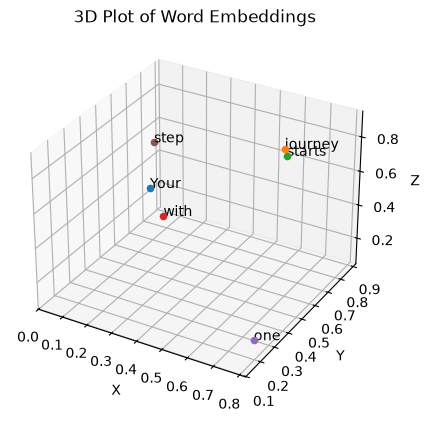

In [40]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Corresponding words
words = ['Your', 'journey', 'starts', 'with', 'one', 'step']

# Extract x, y, z coordinates
x_coords = inputs[:, 0].numpy()
y_coords = inputs[:, 1].numpy()
z_coords = inputs[:, 2].numpy()

# Create 3D plot
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Plot each point and annotate with corresponding word
for x, y, z, word in zip(x_coords, y_coords, z_coords, words):
    ax.scatter(x, y, z)
    ax.text(x, y, z, word, fontsize=10)

# Set labels for axes
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

plt.title('3D Plot of Word Embeddings')
plt.show()

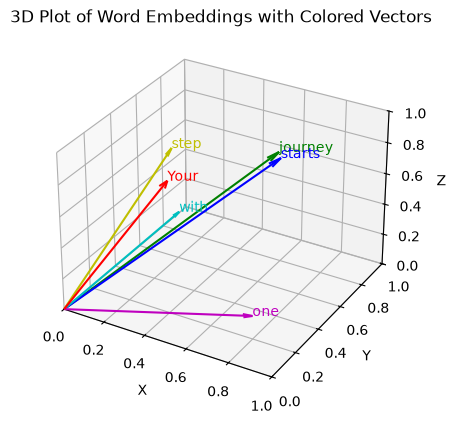

In [41]:
# Create 3D plot with vectors from origin to each point, using different colors
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Define a list of colors for the vectors
colors = ['r', 'g', 'b', 'c', 'm', 'y']

# Plot each vector with a different color and annotate with the corresponding word
for (x, y, z, word, color) in zip(x_coords, y_coords, z_coords, words, colors):
    # Draw vector from origin to the point (x, y, z) with specified color and smaller arrow length ratio
    ax.quiver(0, 0, 0, x, y, z, color=color, arrow_length_ratio=0.05)
    ax.text(x, y, z, word, fontsize=10, color=color)

# Set labels for axes
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

# Set plot limits to keep arrows within the plot boundaries
ax.set_xlim([0, 1])
ax.set_ylim([0, 1])
ax.set_zlim([0, 1])

plt.title('3D Plot of Word Embeddings with Colored Vectors')
plt.show()


In [42]:
query = inputs[1]
attn_scores_2 = torch.empty(inputs.shape[0])
for idx, x_idx in enumerate(inputs):
    attn_scores_2[idx] = torch.dot(x_idx, query)

print(attn_scores_2)


tensor([0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865])


In [43]:
attn_weights_2_tmp = attn_scores_2 / attn_scores_2.sum()

print(f"Attention weights: {attn_weights_2_tmp}")
print(f"Sum: {attn_weights_2_tmp.sum()}")

# or

print(torch.nn.functional.normalize(attn_scores_2, p=1, dim=0))

Attention weights: tensor([0.1455, 0.2278, 0.2249, 0.1285, 0.1077, 0.1656])
Sum: 0.9999998807907104
tensor([0.1455, 0.2278, 0.2249, 0.1285, 0.1077, 0.1656])


In [44]:
def softmax_naive(x):
    return torch.exp(x) / torch.exp(x).sum(dim=0)

attn_scores_2_naive = softmax_naive(attn_scores_2)

print(f"Attention weights: {attn_scores_2_naive}")
print(f"Sum: {attn_scores_2_naive.sum()}")

Attention weights: tensor([0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581])
Sum: 1.0000001192092896


In [45]:
attn_weights_2 = torch.softmax(attn_scores_2, dim=0)

print(f"Attention weights: {attn_weights_2}")
print(f"Sum: {attn_weights_2.sum()}")

Attention weights: tensor([0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581])
Sum: 1.0


In [46]:
query = inputs[1] # 2nd input token is the query

context_vec_2 = torch.zeros(query.shape)
for idx, x_idx in enumerate(inputs):
    context_vec_2 += attn_weights_2[idx] * x_idx

print(context_vec_2)

tensor([0.4419, 0.6515, 0.5683])


In [47]:
attn_scores = torch.empty(6, 6)

for idx, x_idx in enumerate(inputs):
    for jdx, x_jdx in enumerate(inputs):
        attn_scores[idx, jdx] = torch.dot(x_idx, x_jdx)

attn_scores

tensor([[0.9995, 0.9544, 0.9422, 0.4753, 0.4576, 0.6310],
        [0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865],
        [0.9422, 1.4754, 1.4570, 0.8296, 0.7154, 1.0605],
        [0.4753, 0.8434, 0.8296, 0.4937, 0.3474, 0.6565],
        [0.4576, 0.7070, 0.7154, 0.3474, 0.6654, 0.2935],
        [0.6310, 1.0865, 1.0605, 0.6565, 0.2935, 0.9450]])

In [48]:
attn_scores = inputs @ inputs.T
attn_scores

tensor([[0.9995, 0.9544, 0.9422, 0.4753, 0.4576, 0.6310],
        [0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865],
        [0.9422, 1.4754, 1.4570, 0.8296, 0.7154, 1.0605],
        [0.4753, 0.8434, 0.8296, 0.4937, 0.3474, 0.6565],
        [0.4576, 0.7070, 0.7154, 0.3474, 0.6654, 0.2935],
        [0.6310, 1.0865, 1.0605, 0.6565, 0.2935, 0.9450]])

In [49]:
attn_weights = torch.softmax(attn_scores, dim=-1)
attn_weights

tensor([[0.2098, 0.2006, 0.1981, 0.1242, 0.1220, 0.1452],
        [0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581],
        [0.1390, 0.2369, 0.2326, 0.1242, 0.1108, 0.1565],
        [0.1435, 0.2074, 0.2046, 0.1462, 0.1263, 0.1720],
        [0.1526, 0.1958, 0.1975, 0.1367, 0.1879, 0.1295],
        [0.1385, 0.2184, 0.2128, 0.1420, 0.0988, 0.1896]])

In [50]:
all_context_vecs = attn_weights @ inputs

print(f"inputs: \n{inputs}", end="\n\n")
print(f"attn_weights: \n{attn_weights}", end="\n\n")
print(f"all_context_vecs: \n{all_context_vecs}", end="\n\n")

inputs: 
tensor([[0.4300, 0.1500, 0.8900],
        [0.5500, 0.8700, 0.6600],
        [0.5700, 0.8500, 0.6400],
        [0.2200, 0.5800, 0.3300],
        [0.7700, 0.2500, 0.1000],
        [0.0500, 0.8000, 0.5500]])

attn_weights: 
tensor([[0.2098, 0.2006, 0.1981, 0.1242, 0.1220, 0.1452],
        [0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581],
        [0.1390, 0.2369, 0.2326, 0.1242, 0.1108, 0.1565],
        [0.1435, 0.2074, 0.2046, 0.1462, 0.1263, 0.1720],
        [0.1526, 0.1958, 0.1975, 0.1367, 0.1879, 0.1295],
        [0.1385, 0.2184, 0.2128, 0.1420, 0.0988, 0.1896]])

all_context_vecs: 
tensor([[0.4421, 0.5931, 0.5790],
        [0.4419, 0.6515, 0.5683],
        [0.4431, 0.6496, 0.5671],
        [0.4304, 0.6298, 0.5510],
        [0.4671, 0.5910, 0.5266],
        [0.4177, 0.6503, 0.5645]])



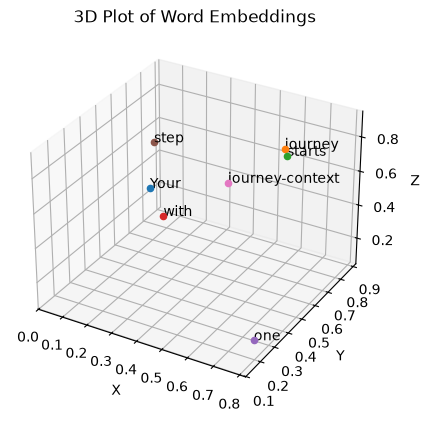

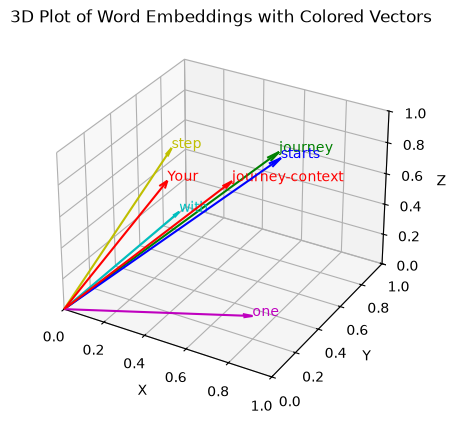

In [51]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

inputs = torch.tensor(
  [[0.43, 0.15, 0.89], # Your     (x^1)
   [0.55, 0.87, 0.66], # journey  (x^2)
   [0.57, 0.85, 0.64], # starts   (x^3)
   [0.22, 0.58, 0.33], # with     (x^4)
   [0.77, 0.25, 0.10], # one      (x^5)
   [0.05, 0.80, 0.55], # step     (x^6)
   [0.4419, 0.6515, 0.5683]]
)

# Corresponding words
words = ['Your', 'journey', 'starts', 'with', 'one', 'step', 'journey-context']

# Extract x, y, z coordinates
x_coords = inputs[:, 0].numpy()
y_coords = inputs[:, 1].numpy()
z_coords = inputs[:, 2].numpy()

# Create 3D plot
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Plot each point and annotate with corresponding word
for x, y, z, word in zip(x_coords, y_coords, z_coords, words):
    ax.scatter(x, y, z)
    ax.text(x, y, z, word, fontsize=10)

# Set labels for axes
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

plt.title('3D Plot of Word Embeddings')
plt.show()

# Create 3D plot with vectors from origin to each point, using different colors
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Define a list of colors for the vectors
colors = ['r', 'g', 'b', 'c', 'm', 'y', 'r']

# Plot each vector with a different color and annotate with the corresponding word
for (x, y, z, word, color) in zip(x_coords, y_coords, z_coords, words, colors):
    # Draw vector from origin to the point (x, y, z) with specified color and smaller arrow length ratio
    ax.quiver(0, 0, 0, x, y, z, color=color, arrow_length_ratio=0.05)
    ax.text(x, y, z, word, fontsize=10, color=color)

# Set labels for axes
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

# Set plot limits to keep arrows within the plot boundaries
ax.set_xlim([0, 1])
ax.set_ylim([0, 1])
ax.set_zlim([0, 1])

plt.title('3D Plot of Word Embeddings with Colored Vectors')
plt.show()

In [52]:
import torch

inputs = torch.tensor(
    [
        [0.43, 0.15, 0.89], # Your
        [0.55, 0.87, 0.66], # journey
        [0.57, 0.85, 0.64], # starts
        [0.22, 0.58, 0.33], # with
        [0.77, 0.25, 0.10], # first
        [0.05, 0.80, 0.55]  # step
    ]
)

In [53]:
x_2 = inputs[1]
d_in = inputs.shape[1]
d_out = 2

d_in, d_out

(3, 2)

In [54]:
torch.manual_seed(123)

W_query = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)
W_key = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)
W_value = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)

In [55]:
print(f"W_query: \n{W_query}", end="\n\n")
print(f"W_key: \n{W_key}", end="\n\n")
print(f"W_value: \n{W_value}", end="\n\n")

W_query: 
Parameter containing:
tensor([[0.2961, 0.5166],
        [0.2517, 0.6886],
        [0.0740, 0.8665]])

W_key: 
Parameter containing:
tensor([[0.1366, 0.1025],
        [0.1841, 0.7264],
        [0.3153, 0.6871]])

W_value: 
Parameter containing:
tensor([[0.0756, 0.1966],
        [0.3164, 0.4017],
        [0.1186, 0.8274]])



In [62]:
queries_2 = x_2 @ W_query
keys_2 = x_2 @ W_key
values_2 = x_2 @ W_value

print(f"queries_2: \n{queries_2}", end="\n\n")
print(f"keys_2: \n{keys_2}", end="\n\n")
print(f"values_2: \n{values_2}", end="\n\n")

queries_2: 
tensor([0.4306, 1.4551])

keys_2: 
tensor([0.4433, 1.1419])

values_2: 
tensor([0.3951, 1.0037])



In [63]:
queries = inputs @ W_query
keys = inputs @ W_key
values = inputs @ W_value

print(f"queries: \n{queries}", end="\n\n")
print(f"keys: \n{keys}", end="\n\n")
print(f"values: \n{values}", end="\n\n")

queries: 
tensor([[0.2309, 1.0966],
        [0.4306, 1.4551],
        [0.4300, 1.4343],
        [0.2355, 0.7990],
        [0.2983, 0.6565],
        [0.2568, 1.0533]])

keys: 
tensor([[0.3669, 0.7646],
        [0.4433, 1.1419],
        [0.4361, 1.1156],
        [0.2408, 0.6706],
        [0.1827, 0.3292],
        [0.3275, 0.9642]])

values: 
tensor([[0.1855, 0.8812],
        [0.3951, 1.0037],
        [0.3879, 0.9831],
        [0.2393, 0.5493],
        [0.1492, 0.3346],
        [0.3221, 0.7863]])



In [69]:
queries_2 @ keys_2

tensor(1.8524)

In [78]:
attn_score_2 = queries_2 @ keys.T
attn_score_2

tensor([1.2705, 1.8524, 1.8111, 1.0795, 0.5577, 1.5440])

In [75]:
attn_score = queries @ keys.T
attn_score

tensor([[0.9231, 1.3545, 1.3241, 0.7910, 0.4032, 1.1330],
        [1.2705, 1.8524, 1.8111, 1.0795, 0.5577, 1.5440],
        [1.2544, 1.8284, 1.7877, 1.0654, 0.5508, 1.5238],
        [0.6973, 1.0167, 0.9941, 0.5925, 0.3061, 0.8475],
        [0.6114, 0.8819, 0.8626, 0.5121, 0.2707, 0.7307],
        [0.8995, 1.3165, 1.2871, 0.7682, 0.3937, 1.0996]])

In [85]:
torch.softmax(attn_score_2, dim=-1)

tensor([0.1401, 0.2507, 0.2406, 0.1157, 0.0687, 0.1842])

In [83]:
d_k = keys.shape[-1]

attn_weights_2 = torch.softmax(attn_score_2 / d_k**0.5, dim=-1)
attn_weights_2

tensor([0.1500, 0.2264, 0.2199, 0.1311, 0.0906, 0.1820])

In [94]:
attn_weights_2 @ values

tensor([0.3061, 0.8210])

In [86]:
import torch

# Define the tensor
tensor = torch.tensor([0.1, -0.2, 0.3, -0.2, 0.5])

# Apply softmax without scaling
softmax_result = torch.softmax(tensor, dim=-1)
print("Softmax without scaling:", softmax_result)

# Multiply the tensor by 8 and then apply softmax
scaled_tensor = tensor * 8
softmax_scaled_result = torch.softmax(scaled_tensor, dim=-1)
print("Softmax after scaling (tensor * 8):", softmax_scaled_result)

Softmax without scaling: tensor([0.1925, 0.1426, 0.2351, 0.1426, 0.2872])
Softmax after scaling (tensor * 8): tensor([0.0326, 0.0030, 0.1615, 0.0030, 0.8000])


In [87]:
d_k = keys.shape[-1]

attn_weights = torch.softmax(attn_score / d_k**0.5, dim=-1)
attn_weights

tensor([[0.1551, 0.2104, 0.2059, 0.1413, 0.1074, 0.1799],
        [0.1500, 0.2264, 0.2199, 0.1311, 0.0906, 0.1820],
        [0.1503, 0.2256, 0.2192, 0.1315, 0.0914, 0.1819],
        [0.1591, 0.1994, 0.1962, 0.1477, 0.1206, 0.1769],
        [0.1610, 0.1949, 0.1923, 0.1501, 0.1265, 0.1752],
        [0.1557, 0.2092, 0.2048, 0.1419, 0.1089, 0.1794]])

In [90]:
attn_weights @ values

tensor([[0.2996, 0.8053],
        [0.3061, 0.8210],
        [0.3058, 0.8203],
        [0.2948, 0.7939],
        [0.2927, 0.7891],
        [0.2990, 0.8040]])

In [96]:
import torch.nn as nn

class SelfAttention_v1(nn.Module):
    def __init__(self, d_in, d_out):
        super().__init__()
        self.W_query = nn.Parameter(torch.rand(d_in, d_out))
        self.W_key = nn.Parameter(torch.rand(d_in, d_out))
        self.W_value = nn.Parameter(torch.rand(d_in, d_out))
    
    def forward(self, x):
        keys = x @ self.W_key
        values = x @ self.W_value
        queries = x @ self.W_query

        attn_score = queries @ keys.T
        att_weight = torch.softmax(attn_score / keys.shape[-1] ** 0.5, dim=-1)
        context_vec = attn_weights @ values
        return context_vec

In [98]:
torch.manual_seed(123)
sa_v1 = SelfAttention_v1(d_in, d_out)
sa_v1(inputs)

tensor([[0.2996, 0.8053],
        [0.3061, 0.8210],
        [0.3058, 0.8203],
        [0.2948, 0.7939],
        [0.2927, 0.7891],
        [0.2990, 0.8040]], grad_fn=<MmBackward0>)

In [106]:
class SelfAttention_v2(nn.Module):
    def __init__(self, d_in, d_out, qkv_bais=False):
        super().__init__()
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bais)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bais)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bais)

    def forward(self, x):
        keys = self.W_key(x)
        values = self.W_value(x)
        queries = self.W_query(x)

        attn_score = queries @ keys.T
        attn_weights = torch.softmax(attn_score / keys.shape[-1] ** 0.5, dim=-1)
        context_vec = attn_weights @ values
        return context_vec

In [110]:
torch.manual_seed(123)
sa_v1 = SelfAttention_v2(d_in, d_out)
sa_v1(inputs)

tensor([[-0.5337, -0.1051],
        [-0.5323, -0.1080],
        [-0.5323, -0.1079],
        [-0.5297, -0.1076],
        [-0.5311, -0.1066],
        [-0.5299, -0.1081]], grad_fn=<MmBackward0>)